In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from wiki_forecast.baselines import naive, seasonal_naive
from wiki_forecast.evaluation import backtest, summarize

df = pd.read_parquet("../data/raw/oktoberfest.parquet")
s = df.set_index("date")["views"].asfreq("D")

In [2]:
results = pd.concat(
    [
        backtest(s, naive, "naive"),
        backtest(s, seasonal_naive(7), "snaive_7"),
        backtest(s, seasonal_naive(364), "snaive_364"),
    ],
    ignore_index=True,
)
summarize(results)

,MAE,MASE
model,,
snaive_364,438.300824,0.968386
snaive_7,767.195055,1.683036
naive,807.986264,1.772697


In [3]:
festival = results[results["date"].dt.month.isin([9, 10])]
summarize(festival)

,MAE,MASE
model,,
snaive_364,1299.783333,2.892645
snaive_7,3490.225000,7.700616
naive,4016.358333,8.827451


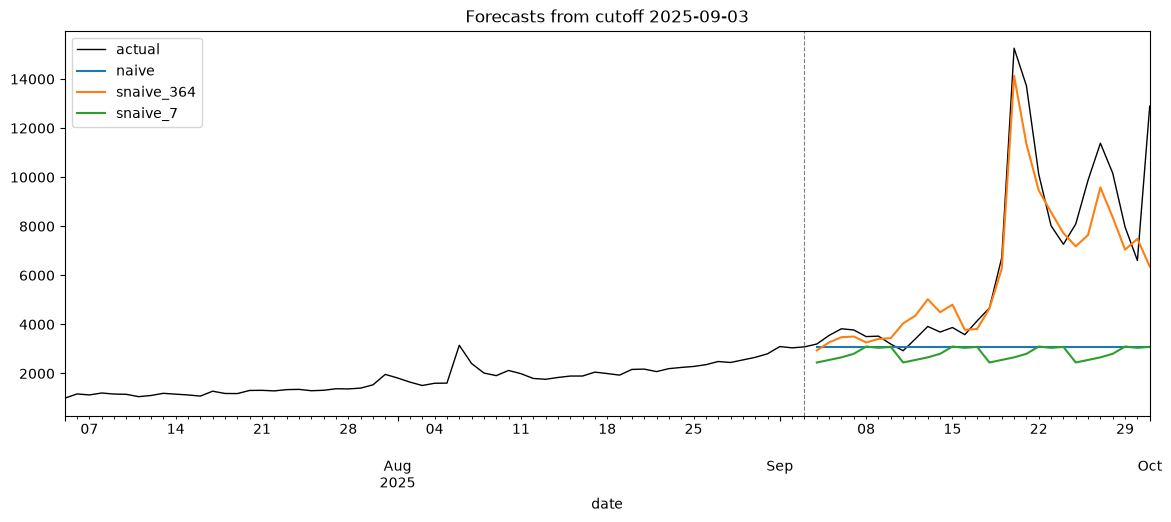

In [4]:
cutoffs = results["cutoff"].unique()
c = min(cutoffs, key=lambda x: abs(x - pd.Timestamp("2025-09-10")))
fold = results[results["cutoff"] == c]

fig, ax = plt.subplots(figsize=(14, 5))
s[c - pd.Timedelta(days=60) : fold["date"].max()].plot(ax=ax, color="black", lw=1, label="actual")
for name, g in fold.groupby("model"):
    ax.plot(g["date"], g["pred"], lw=1.5, label=name)
ax.axvline(c, color="gray", ls="--", lw=0.8)
ax.set_title(f"Forecasts from cutoff {c.date()}")
ax.legend()
plt.show()

In [5]:
results_long = pd.concat(
    [
        backtest(s, naive, "naive", n_folds=55),
        backtest(s, seasonal_naive(7), "snaive_7", n_folds=55),
        backtest(s, seasonal_naive(364), "snaive_364", n_folds=55),
    ],
    ignore_index=True,
)

# Error per model and per year
results_long["year"] = results_long["date"].dt.year
results_long.groupby("year").apply(summarize, include_groups=False)

MAE      MASE
year model                            
2022 snaive_364   847.349650  1.861063
     naive       1656.426573  3.627558
     snaive_7    2350.489510  5.076536
2023 snaive_364   231.978082  0.499610
     naive        872.449315  1.880817
     snaive_7    1072.463014  2.301578
2024 snaive_364   310.478142  0.677659
     naive        624.581967  1.357426
     snaive_7     771.251366  1.671064
2025 snaive_364   276.901370  0.607615
     snaive_7     927.180822  2.028489
     naive       1112.912329  2.432756
2026 naive        536.956811  1.194471
     snaive_7     599.451827  1.332569
     snaive_364   702.056478  1.558314